In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

features = [
    "age", "Medu", "Fedu", "traveltime",
    "studytime", "failures", "famrel",
    "freetime", "goout", "Dalc", "Walc",
    "health", "absences"
]

X = df[features]
y = (df["G3"] >= 10).astype(int)

print("Total students:", len(df))
print("\nClass distribution:")
print(y.map({0: "Fail", 1: "Pass"}).value_counts())

Total students: 395

Class distribution:
G3
Pass    265
Fail    130
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced",max_iter=1000)
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

Accuracy:  0.633
Precision: 0.750
Recall:    0.679
F1-score:  0.713

Classification report:
              precision    recall  f1-score   support

        Fail       0.45      0.54      0.49        26
        Pass       0.75      0.68      0.71        53

    accuracy                           0.63        79
   macro avg       0.60      0.61      0.60        79
weighted avg       0.65      0.63      0.64        79



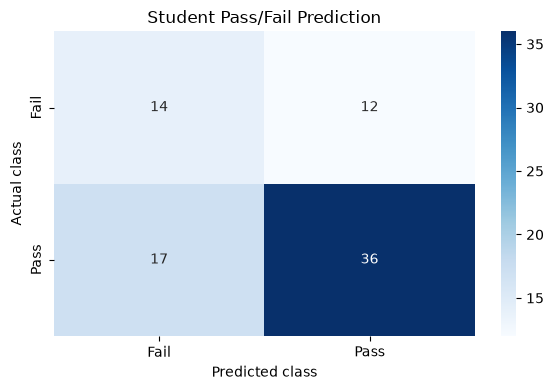

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Student Pass/Fail Prediction")
plt.tight_layout()
plt.show()

In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

features = [
    "age", "Medu", "Fedu", "traveltime", "studytime",
    "failures", "famrel", "freetime", "goout", "Dalc",
    "Walc", "health", "absences"
]

X = df[features]
y = (df["G3"] >= 10).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Balanced Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=42,
        class_weight="balanced"
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=42,
        class_weight="balanced"
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "recall": "recall"
        },
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    report = classification_report(
        y_test, pred, output_dict=True, zero_division=0
    )

    results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Pass F1": scores["test_f1"].mean(),
        "CV Pass Recall": scores["test_recall"].mean(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Fail Recall": report["0"]["recall"],
        "Test Fail F1": report["0"]["f1-score"]
    })

results_df = pd.DataFrame(results).sort_values(
    "Test Fail Recall", ascending=False
)
print(results_df.round(3).to_string(index=False))


                       Model  CV Accuracy  CV Pass F1  CV Pass Recall  Test Accuracy  Test Fail Recall  Test Fail F1
Balanced Logistic Regression        0.652       0.734           0.717          0.633             0.538         0.491
               Random Forest        0.690       0.771           0.778          0.646             0.500         0.481
               Decision Tree        0.706       0.799           0.872          0.658             0.500         0.491
                 Extra Trees        0.681       0.766           0.783          0.633             0.423         0.431
         Logistic Regression        0.700       0.798           0.886          0.658             0.269         0.341


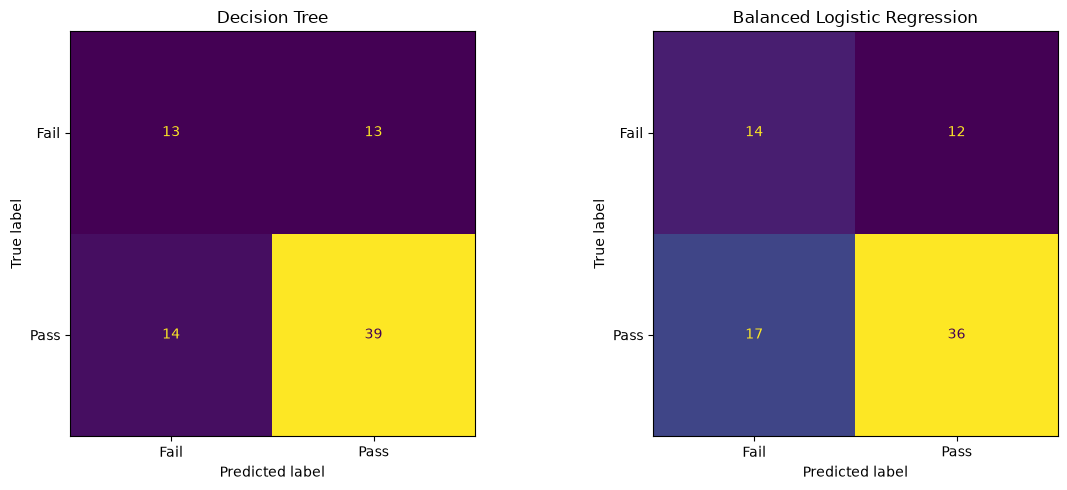

Confusion matrices saved successfully.


In [4]:

import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

candidates = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ),
    "Balanced Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, candidates.items()):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=[0, 1],
        display_labels=["Fail", "Pass"],
        ax=ax,
        values_format="d",
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)
fig.savefig(
    "../reports/figures/classification_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")


In [5]:
import os

print(os.path.exists(
    "../reports/figures/classification_confusion_matrices.png"
))

True
